In [1]:
import sys
import os

from matplotlib import pyplot as plt

import numpy as np
import pandas as pd

from sklearn.decomposition import PCA
from sklearn.cross_decomposition import CCA


sys.path.append(os.path.join(os.getcwd(), '../import'))

from utils import read_utils
from utils import plot_utils
from utils import train_utils

In [2]:
plot_id = 14
dims =2

selection_n = ['DD01', 'VB02', 'SMDDR', 'AVAR']
selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

In [3]:
path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gcamp')
file_ids, filenames, continuous_behaviors, discrete_states, eigenworms, kymographs, traces = read_utils.get_data(path)

for i in range(len(filenames)):
	mask = eigenworms[i].notna().all(axis=1)
	#continuous_behaviors[i] = continuous_behaviors[i][mask]
	discrete_states[i] = discrete_states[i][mask]
	eigenworms[i] = eigenworms[i][mask]
	traces[i] = traces[i][mask]

	#kymographs[i] = kymographs[i][mask]
	#filenames[i] = filenames[i][mask]

# discrete_states = [ds[selection_bhl] for ds in discrete_states]

In [4]:
(modes_manifold, modes_manifold_b,
 recos_manifold, recos_manifold_b,
 loads_cca_man, loads_cca_man_b,
 vars_expl_mans, vars_expl_mans_rs) = train_utils.get_manifolds(traces,
																[ds[selection_bhl] for ds in discrete_states],
																n_cc=dims, n_pc=5)

0.42925377362858796 0.689406966642158


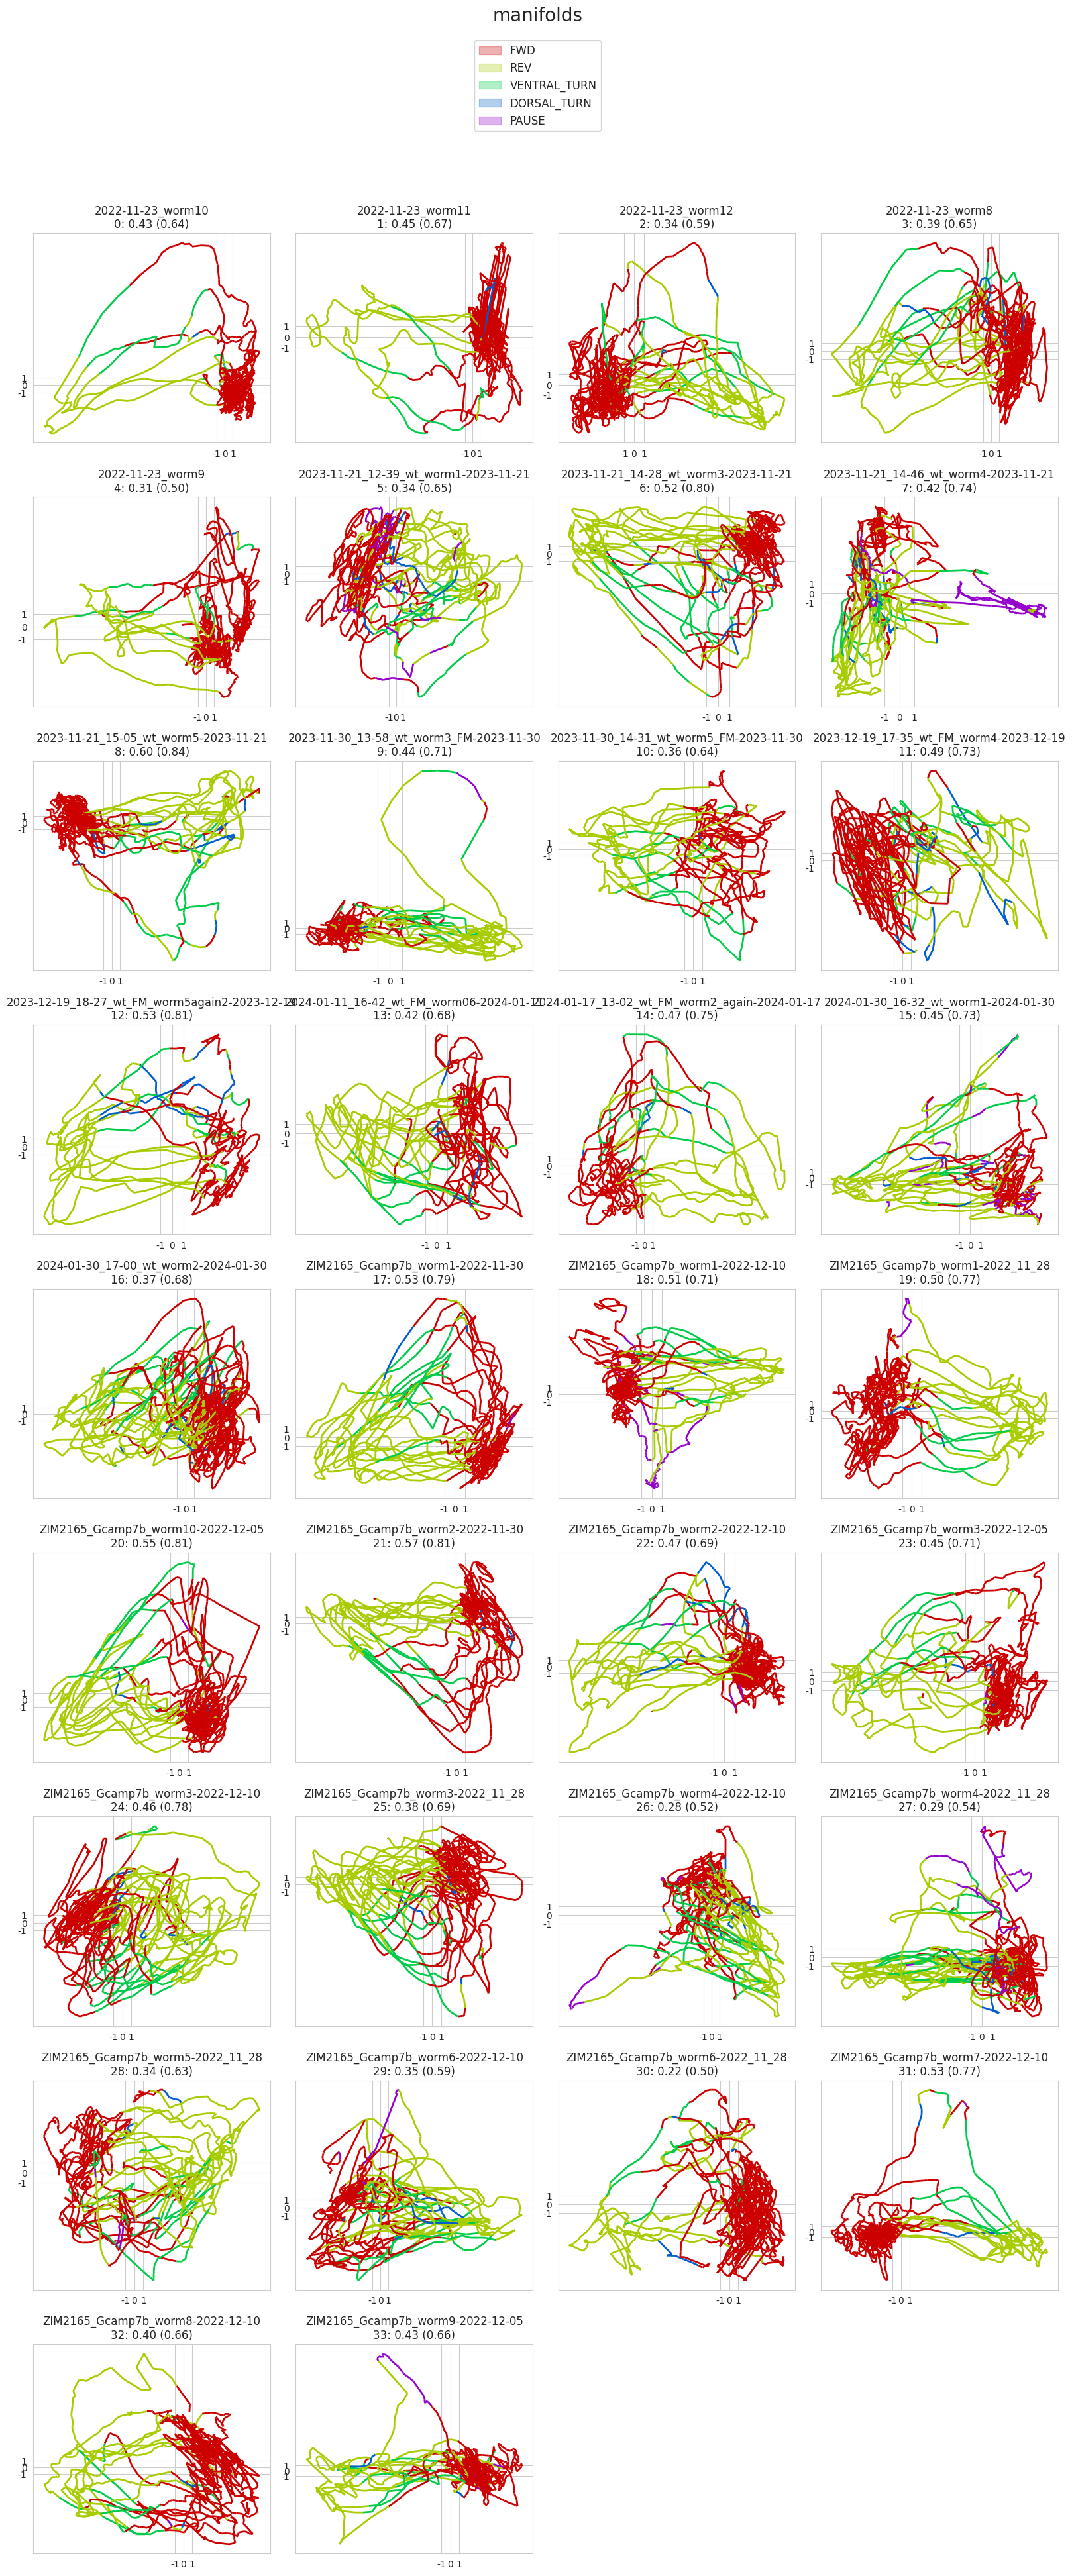

In [8]:
plot_utils.plot_manifolds(filenames, modes_manifold, [ds[['FWD'] + selection_bhl] for ds in discrete_states], vars_expl_mans, vars_expl_mans_rs,
						  top_space=3.5)

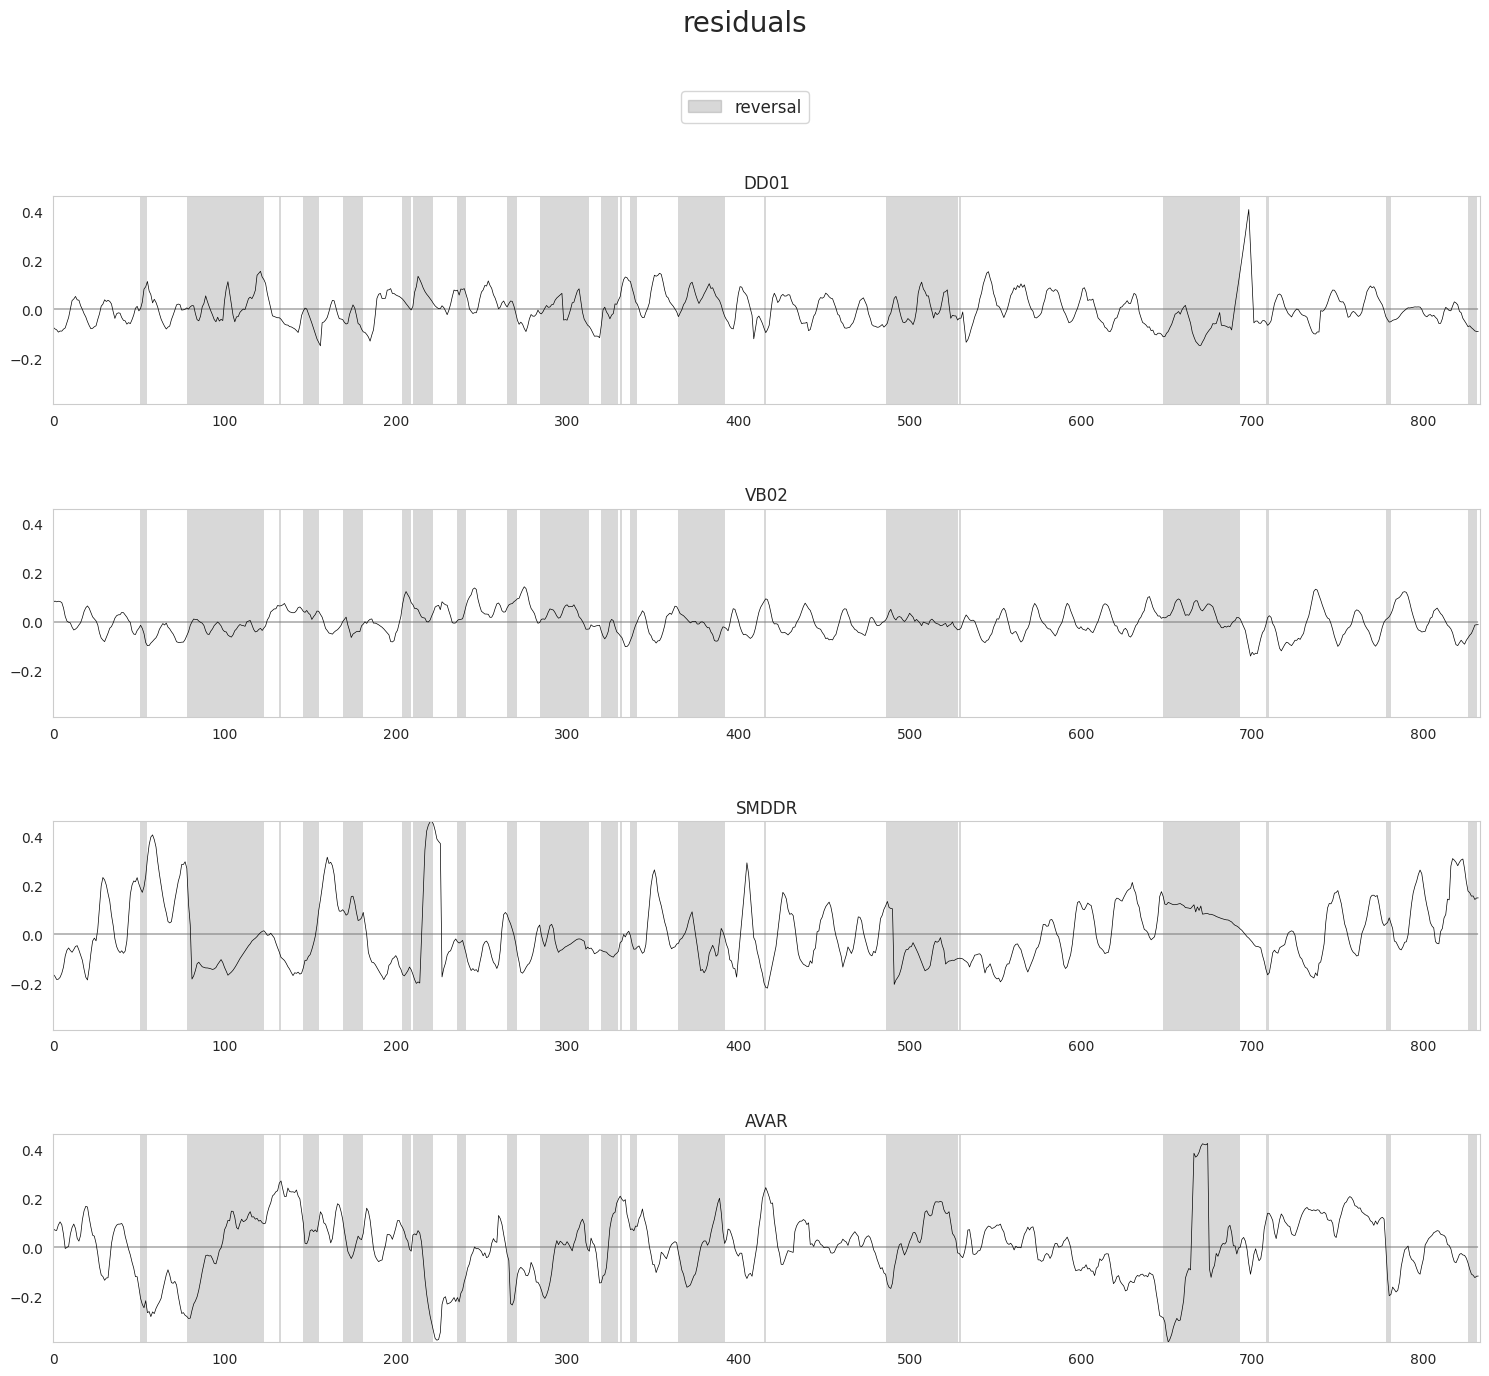

In [9]:
traces_residual = [trace - trace_man for trace, trace_man in zip(traces, recos_manifold)]

plot_utils.plot_traces('residuals',
					   discrete_states[file_ids.index(plot_id)]['REV'],
					   traces_residual[file_ids.index(plot_id)][selection_n],
					   n_plots=None, plots_per_row=1, ylimits=None)